# 05 - Phase 5: Models and Alignment

**Inputs (Add Input):** the Phase 4 output dataset (e.g. `cdb2m-phase4`) that contains  
`X_region.npy`, `X_maxent.npy`, `X_shuffled.npy`, `X_randnoise.npy`,  
`M_region.csv`, `folds.json`, `real_stimuli.npz`, `synth_suite.npz`, `cdb2m_lib.py`.

**Settings:** Accelerator **GPU T4 or P100**, Internet **Off**. Runtime approx 30-60 min.

| Step | Cell | What it does |
|------|------|--------------|
| 5.1 | A-B  | RNN baseline (SeqGRU, no alignment) |
| 5.2 | C    | InfoNCE alignment loss |
| 5.3 | D    | Linear CKA metric |
| 5.4 | E-F  | Train all 5 conditions x 3 seeds, evaluate on full synthetic suite |
| 5.5 | G-H  | Reproduce B2M effect: delta_B2M table, accuracy bars, CKA plot |
| Save | I   | Persist results, checkpoints, and figures for Phase 6 |

In [1]:
# ---- Cell A: setup and load Phase 4 outputs ----
import os, sys, json, pathlib, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

OUT5 = pathlib.Path("/kaggle/working/phase5_out")
OUT5.mkdir(parents=True, exist_ok=True)

def find(name):
    hits = []
    for root in ("/kaggle/input", "/kaggle/working"):
        hits += sorted(pathlib.Path(root).rglob(name))
    assert hits, f"{name} not found - add the Phase 4 dataset as input"
    return hits[0]

P4 = find("X_region.npy").parent
print("Phase 4 files from:", P4)

sys.path.insert(0, str(P4))
import importlib, cdb2m_lib
importlib.reload(cdb2m_lib)
from cdb2m_lib import *

# ---- load all brain conditions ----
brain_data = {
    "real":      np.load(P4 / "X_region.npy"),
    "maxent":    np.load(P4 / "X_maxent.npy"),
    "shuffled":  np.load(P4 / "X_shuffled.npy"),
    "randnoise": np.load(P4 / "X_randnoise.npy"),
}

M = pd.read_csv(P4 / "M_region.csv")
C = M.clean.astype(bool).values

with open(P4 / "folds.json") as fp:
    folds = json.load(fp)

stim      = np.load(P4 / "real_stimuli.npz", allow_pickle=True)
suite_raw = np.load(P4 / "synth_suite.npz",  allow_pickle=True)

X_tok    = stim["X_tok"]
y_tok    = stim["y"]
n_tokens = int(stim["n_tokens"])

X_tok_c  = X_tok[C]
y_tok_c  = y_tok[C].astype(np.int64)
N_clean  = int(C.sum())

suite_keys = ["id_4_6", "size_8", "len_10", "len_12", "unseen_letters"]
suite = {k: (suite_raw[f"{k}_X"], suite_raw[f"{k}_y"].astype(np.int64))
         for k in suite_keys}

print(f"X shape: {brain_data['real'].shape}   clean: {N_clean}")
print(f"X_tok: {X_tok_c.shape}   n_tokens: {n_tokens}")
print(f"Synthetic suite splits: {suite_keys}")

Device: cuda
Phase 4 files from: /kaggle/input/datasets/rachana240906/cdb2m-phase4/phase4_out
X shape: (3353, 4, 16, 5)   clean: 3185
X_tok: (3185, 14)   n_tokens: 22
Synthetic suite splits: ['id_4_6', 'size_8', 'len_10', 'len_12', 'unseen_letters']


## 5.1 RNN Baseline

The `SeqGRU` from `cdb2m_lib` maps a token sequence to a binary classification.  
When `return_rep=True` it also returns the final GRU hidden state `h` (the model representation  
that will be aligned to brain embeddings in Step 5.2).

In [2]:
# ---- Cell B: 5.1 - RNN + BrainEncoder smoke test ----
torch.manual_seed(0)
demo_gru = SeqGRU(n_tokens).to(device)
demo_x   = torch.as_tensor(X_tok_c[:8], device=device)
logits, h = demo_gru(demo_x, return_rep=True)
print("SeqGRU logits:", logits.shape, "  hidden rep:", h.shape)
print("SeqGRU params:", sum(p.numel() for p in demo_gru.parameters()))

enc = BrainEncoder().to(device)
demo_xb = torch.as_tensor(brain_data["real"][C][:8], device=device)
z = enc(demo_xb)
print("BrainEncoder output z:", z.shape)
print("BrainEncoder params:", sum(p.numel() for p in enc.parameters()))

SeqGRU logits: torch.Size([8, 2])   hidden rep: torch.Size([8, 128])
SeqGRU params: 63170
BrainEncoder output z: torch.Size([8, 32])
BrainEncoder params: 27232


## 5.2 InfoNCE Alignment Loss

InfoNCE pulls together the brain embedding `z` and the RNN hidden state `h` for the same  
trial (positive pair) and pushes apart representations from different trials (negatives).  

$$L_{align} = -\frac{1}{B}\sum_{i} \log \frac{\exp(\text{sim}(z_i, h_i)/\tau)}{\sum_{j} \exp(\text{sim}(z_i, h_j)/\tau)}$$

In [3]:
# ---- Cell C: 5.2 - InfoNCE loss ----
def infonce_loss(z, h, tau=0.07):
    """
    Symmetric InfoNCE between brain embeddings z (B, d_z) and RNN reps h (B, d_h).
    Both are L2-normalised before computing cosine similarities.
    """
    z = F.normalize(z, dim=1)
    h = F.normalize(h, dim=1)
    logits_zh = z @ h.T / tau          # (B, B)
    logits_hz = h @ z.T / tau
    labels = torch.arange(len(z), device=z.device)
    return 0.5 * (F.cross_entropy(logits_zh, labels) + F.cross_entropy(logits_hz, labels))

# smoke tests
torch.manual_seed(0)
z_t = torch.randn(16, 32, device=device)
h_t = torch.randn(16, 32, device=device)
print(f"InfoNCE random  (expect ~log(16)={np.log(16):.2f}): {infonce_loss(z_t, h_t).item():.3f}")
print(f"InfoNCE perfect (expect ~0):                        {infonce_loss(z_t, z_t).item():.3f}")

InfoNCE random  (expect ~log(16)=2.77): 5.903
InfoNCE perfect (expect ~0):                        0.000


## 5.3 Linear CKA

Centred Kernel Alignment (Kornblith et al. 2019) measures representational similarity  
between two embedding matrices without requiring the same dimension.  
CKA = 1 means isomorphic geometry; CKA = 0 means orthogonal structure.

In [4]:
# ---- Cell D: 5.3 - Linear CKA ----
def linear_cka(X, Y):
    "Linear CKA between (n, p) and (n, q) numpy arrays."
    n = X.shape[0]
    X = X - X.mean(0, keepdims=True)
    Y = Y - Y.mean(0, keepdims=True)
    hsic_xy = np.linalg.norm(Y.T @ X) ** 2 / (n - 1) ** 2
    hsic_xx = np.linalg.norm(X.T @ X) ** 2 / (n - 1) ** 2
    hsic_yy = np.linalg.norm(Y.T @ Y) ** 2 / (n - 1) ** 2
    denom = np.sqrt(hsic_xx * hsic_yy)
    return float(hsic_xy / denom) if denom > 0 else 0.0

rng = np.random.default_rng(0)
A = rng.standard_normal((100, 32))
print(f"CKA(A, A+noise) = {linear_cka(A, A + 0.01*rng.standard_normal((100, 32))):.4f}  (expect near 1)")
print(f"CKA(A, random)  = {linear_cka(A, rng.standard_normal((100, 64))):.4f}  (expect near 0)")

CKA(A, A+noise) = 0.9999  (expect near 1)
CKA(A, random)  = 0.3087  (expect near 0)


## 5.4 Training – all conditions x seeds

| Condition | Brain data | Alignment |
|-----------|-----------|----------|
| `no_align` | — | None (task loss only) |
| `real` | X_region.npy | InfoNCE |
| `maxent` | X_maxent.npy | InfoNCE |
| `shuffled` | X_shuffled.npy | InfoNCE |
| `randnoise` | X_randnoise.npy | InfoNCE |

Config: 3 seeds, lambda=1.0, tau=0.07, 5 000 steps. Lambda sweep is Phase 6.

In [5]:
# ---- Cell E: config and helpers ----
LAMBDA = 1.0
TAU    = 0.07
STEPS  = 5000
BS     = 64
LR     = 3e-3
SEEDS  = [0, 1, 2]
D_PROJ = 32          # must match BrainEncoder d_out

CONDITIONS = ["no_align", "real", "maxent", "shuffled", "randnoise"]

class ProjectionHead(nn.Module):
    "Projects GRU hidden (128-d) to same space as BrainEncoder output (32-d) for InfoNCE."
    def __init__(self, d_in=128, d_out=32):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, d_in), nn.GELU(), nn.Linear(d_in, d_out))
    def forward(self, x): return self.net(x)

def make_models(seed):
    torch.manual_seed(seed)
    gru  = SeqGRU(n_tokens).to(device)
    head = ProjectionHead().to(device)
    enc  = BrainEncoder().to(device)
    return gru, head, enc

@torch.no_grad()
def evaluate(gru, Xseq, yseq):
    gru.eval()
    pred = gru(torch.as_tensor(Xseq, device=device)).argmax(1).cpu().numpy()
    y    = np.asarray(yseq)
    tp = ((pred == 1) & (y == 1)).sum(); pp = (y == 1).sum()
    tn = ((pred == 0) & (y == 0)).sum(); pn = (y == 0).sum()
    gru.train()
    return float(0.5 * (tp / max(pp, 1) + tn / max(pn, 1)))

@torch.no_grad()
def compute_cka(gru, head, enc, X_brain, X_seq):
    gru.eval(); head.eval(); enc.eval()
    all_z, all_h = [], []
    for i in range(0, len(X_seq), 256):
        xb = torch.as_tensor(X_brain[i:i+256], device=device)
        xs = torch.as_tensor(X_seq[i:i+256],   device=device)
        _, hrep = gru(xs, return_rep=True)
        all_z.append(enc(xb).cpu().numpy())
        all_h.append(head(hrep).cpu().numpy())
    gru.train(); head.train(); enc.train()
    return linear_cka(np.concatenate(all_z), np.concatenate(all_h))

print("Config OK:", CONDITIONS, "| Seeds:", SEEDS, "| Steps:", STEPS)

Config OK: ['no_align', 'real', 'maxent', 'shuffled', 'randnoise'] | Seeds: [0, 1, 2] | Steps: 5000


In [6]:
# ---- Cell F: 5.4 - full training loop (30-50 min on GPU) ----
Xt_c = torch.as_tensor(X_tok_c, device=device)
yt_c = torch.as_tensor(y_tok_c, device=device)

ckpt_dir = OUT5 / "checkpoints"
ckpt_dir.mkdir(exist_ok=True)

all_rows = []
t0 = time.time()

for cond in CONDITIONS:
    use_align  = (cond != "no_align")
    X_brain_c  = brain_data[cond][C] if use_align else None

    for seed in SEEDS:
        gru, head, enc = make_models(seed)
        params = list(gru.parameters()) + list(head.parameters())
        if use_align:
            params += list(enc.parameters())
        opt = torch.optim.Adam(params, lr=LR)

        task_hist, align_hist = [], []
        rng_tr = np.random.default_rng(seed + 100)

        for step in range(STEPS):
            idx = rng_tr.integers(0, N_clean, BS)
            logits, hrep = gru(Xt_c[idx], return_rep=True)
            t_loss = F.cross_entropy(logits, yt_c[idx])

            if use_align:
                xb    = torch.as_tensor(X_brain_c[idx], device=device)
                a_loss = infonce_loss(enc(xb), head(hrep), tau=TAU)
                loss   = t_loss + LAMBDA * a_loss
                align_hist.append(a_loss.item())
            else:
                loss = t_loss
                align_hist.append(0.0)

            task_hist.append(t_loss.item())
            opt.zero_grad(); loss.backward(); opt.step()

        # evaluate
        row = dict(condition=cond, seed=seed)
        for split_name, (Xs, ys) in suite.items():
            row[split_name] = evaluate(gru, Xs, ys)

        # CKA vs real brain (even for no_align and controls)
        row["cka"] = compute_cka(gru, head, enc, brain_data["real"][C], X_tok_c)

        row["final_task_loss"]  = float(np.mean(task_hist[-200:]))
        row["final_align_loss"] = float(np.mean(align_hist[-200:]))
        all_rows.append(row)

        torch.save({"gru": gru.state_dict(), "head": head.state_dict(),
                    "enc":  enc.state_dict()},
                   ckpt_dir / f"{cond}_seed{seed}.pt")

        elapsed = time.time() - t0
        print(f"[{elapsed:5.0f}s] {cond:12s} seed={seed}  "
              f"id_4_6={row['id_4_6']:.3f}  size_8={row['size_8']:.3f}  "
              f"unseen={row['unseen_letters']:.3f}  CKA={row['cka']:.4f}")

results = pd.DataFrame(all_rows)
results.to_csv(OUT5 / "results_raw.csv", index=False)
print("\nDone. results_raw.csv saved.")
print(results.groupby("condition")[suite_keys].mean().round(3).to_string())

[   19s] no_align     seed=0  id_4_6=0.700  size_8=0.675  unseen=0.572  CKA=0.0028
[   31s] no_align     seed=1  id_4_6=0.729  size_8=0.648  unseen=0.545  CKA=0.0031
[   42s] no_align     seed=2  id_4_6=0.681  size_8=0.644  unseen=0.616  CKA=0.0043
[   73s] real         seed=0  id_4_6=0.736  size_8=0.695  unseen=0.589  CKA=0.7001
[  104s] real         seed=1  id_4_6=0.707  size_8=0.688  unseen=0.527  CKA=0.6976
[  134s] real         seed=2  id_4_6=0.699  size_8=0.657  unseen=0.670  CKA=0.6721
[  165s] maxent       seed=0  id_4_6=0.722  size_8=0.674  unseen=0.647  CKA=0.0161
[  196s] maxent       seed=1  id_4_6=0.729  size_8=0.653  unseen=0.641  CKA=0.0228
[  226s] maxent       seed=2  id_4_6=0.687  size_8=0.635  unseen=0.567  CKA=0.0287
[  256s] shuffled     seed=0  id_4_6=0.707  size_8=0.658  unseen=0.541  CKA=0.0199
[  287s] shuffled     seed=1  id_4_6=0.683  size_8=0.660  unseen=0.538  CKA=0.0340
[  317s] shuffled     seed=2  id_4_6=0.708  size_8=0.640  unseen=0.623  CKA=0.0420
[  3

## 5.5 Reproduce the B2M Effect

Delta_B2M = acc(real) - max(acc(maxent), acc(shuffled), acc(randnoise))

A positive delta on OOD splits (size_8, len_10, len_12, unseen_letters) is the core finding.

In [7]:
# ---- Cell G: 5.5 - B2M effect table ----
summ = results.groupby("condition")[suite_keys + ["cka"]].agg(["mean", "sem"]).round(4)
print("=== Mean +/- SEM across seeds ===")
print(summ.to_string())

mean_by_cond  = results.groupby("condition")[suite_keys].mean()
controls_mean = mean_by_cond.loc[["maxent", "shuffled", "randnoise"]].max()
real_mean     = mean_by_cond.loc["real"]
delta_b2m     = real_mean - controls_mean

print("\n=== Delta_B2M (real - max control) ===")
for split in suite_keys:
    tag = "BETTER" if delta_b2m[split] > 0 else "WORSE"
    print(f"  {split:20s}  delta={delta_b2m[split]:+.4f}  [{tag}]")

delta_b2m.to_frame("delta_b2m").to_csv(OUT5 / "delta_b2m.csv")

cka_summ = results.groupby("condition")["cka"].agg(["mean", "sem"]).round(4)
print("\n=== CKA to real brain (all conditions) ===")
print(cka_summ.to_string())
cka_summ.to_csv(OUT5 / "cka_summary.csv")

=== Mean +/- SEM across seeds ===
           id_4_6          size_8          len_10          len_12         unseen_letters             cka        
             mean     sem    mean     sem    mean     sem    mean     sem           mean     sem    mean     sem
condition                                                                                                       
maxent     0.7127  0.0130  0.6540  0.0113  0.6303  0.0154  0.5827  0.0193         0.6183  0.0257  0.0226  0.0036
no_align   0.7033  0.0140  0.6557  0.0097  0.6373  0.0063  0.6233  0.0030         0.5777  0.0207  0.0034  0.0005
randnoise  0.6950  0.0074  0.6497  0.0055  0.6280  0.0031  0.5863  0.0055         0.5493  0.0144  0.0308  0.0049
real       0.7140  0.0112  0.6800  0.0117  0.6407  0.0064  0.5940  0.0160         0.5953  0.0414  0.6899  0.0089
shuffled   0.6993  0.0082  0.6527  0.0064  0.6237  0.0143  0.5720  0.0097         0.5673  0.0278  0.0320  0.0065

=== Delta_B2M (real - max control) ===
  id_4_6              

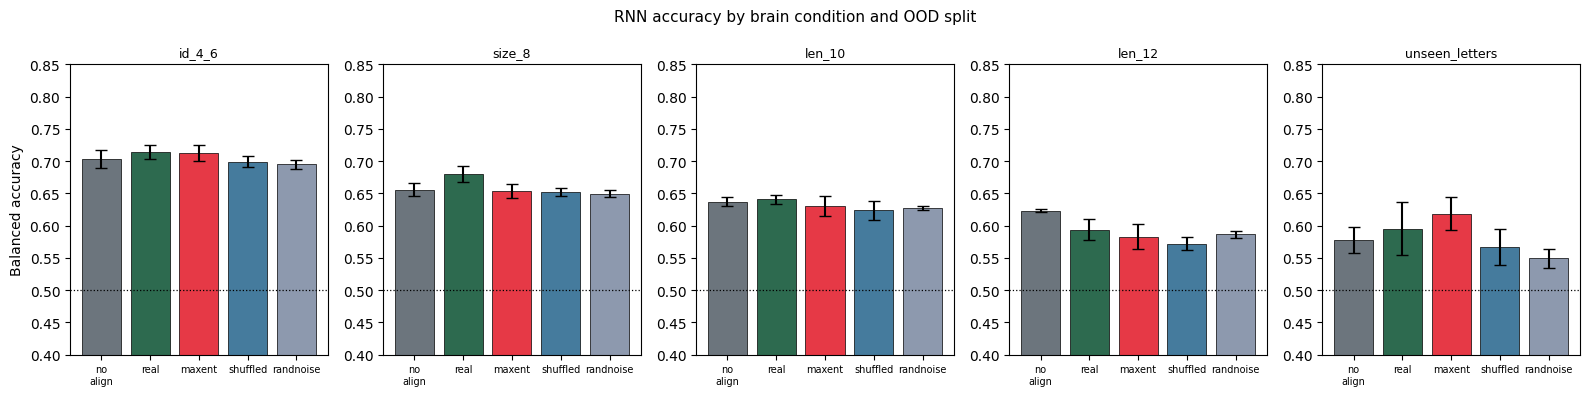

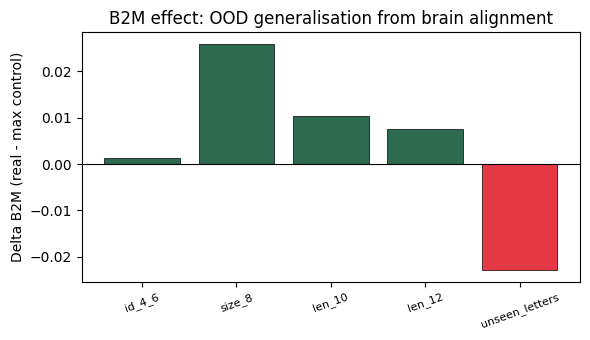

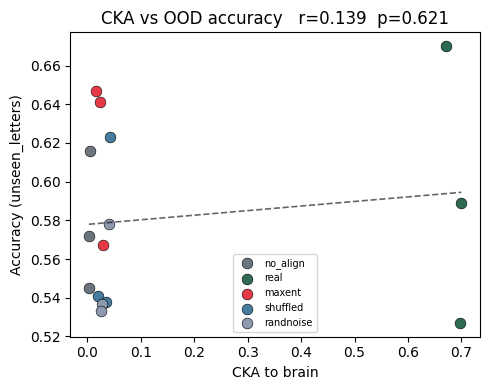

All figures saved.


In [8]:
# ---- Cell H: figures ----
COND_COLORS = {
    "no_align":  "#6c757d",
    "real":      "#2d6a4f",
    "maxent":    "#e63946",
    "shuffled":  "#457b9d",
    "randnoise": "#8d99ae",
}
COND_ORDER = ["no_align", "real", "maxent", "shuffled", "randnoise"]

# Fig 1: accuracy per condition per split
fig, axes = plt.subplots(1, len(suite_keys), figsize=(16, 4), sharey=False)
for ax, split in zip(axes, suite_keys):
    means = results.groupby("condition")[split].mean().reindex(COND_ORDER)
    sems  = results.groupby("condition")[split].sem().reindex(COND_ORDER)
    ax.bar(range(len(COND_ORDER)), means, yerr=sems,
           color=[COND_COLORS[c] for c in COND_ORDER],
           capsize=4, edgecolor="k", linewidth=0.5)
    ax.axhline(0.5, color="k", ls=":", lw=0.9)
    ax.set_xticks(range(len(COND_ORDER)))
    ax.set_xticklabels([c.replace("_", "\n") for c in COND_ORDER], fontsize=7)
    ax.set_title(split, fontsize=9)
    ax.set_ylim(0.4, 0.85)
    ax.set_ylabel("Balanced accuracy" if ax is axes[0] else "")

fig.suptitle("RNN accuracy by brain condition and OOD split", fontsize=11)
plt.tight_layout()
plt.savefig(OUT5 / "fig_accuracy_by_condition.png", dpi=120)
plt.show()

# Fig 2: Delta_B2M
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(range(len(suite_keys)), delta_b2m.values,
       color=["#2d6a4f" if v > 0 else "#e63946" for v in delta_b2m.values],
       edgecolor="k", linewidth=0.5)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(suite_keys))); ax.set_xticklabels(suite_keys, rotation=20, fontsize=8)
ax.set_ylabel("Delta B2M (real - max control)")
ax.set_title("B2M effect: OOD generalisation from brain alignment")
plt.tight_layout()
plt.savefig(OUT5 / "fig_delta_b2m.png", dpi=120)
plt.show()

# Fig 3: CKA vs OOD accuracy scatter
from scipy.stats import pearsonr
fig, ax = plt.subplots(figsize=(5, 4))
for cond in COND_ORDER:
    sub = results[results.condition == cond]
    ax.scatter(sub.cka, sub.unseen_letters,
               color=COND_COLORS[cond], label=cond, s=60, edgecolors="k", lw=0.4)

x_all = results.cka.values; y_all = results.unseen_letters.values
coef = np.polyfit(x_all, y_all, 1)
xline = np.linspace(x_all.min(), x_all.max(), 100)
ax.plot(xline, np.polyval(coef, xline), "k--", lw=1.2, alpha=0.6)
r, p = pearsonr(x_all, y_all)
ax.set_xlabel("CKA to brain"); ax.set_ylabel("Accuracy (unseen_letters)")
ax.set_title(f"CKA vs OOD accuracy   r={r:.3f}  p={p:.3f}")
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT5 / "fig_cka_vs_acc.png", dpi=120)
plt.show()
print("All figures saved.")

In [9]:
# ---- Cell I: save all outputs and copy Phase 4 artifacts forward ----
import shutil

summ.to_csv(OUT5 / "results_summary.csv")

p4_files = ["X_region.npy", "X_maxent.npy", "X_shuffled.npy", "X_randnoise.npy",
            "M_region.csv", "folds.json", "fold_summary.csv",
            "real_stimuli.npz", "synth_suite.npz", "ceiling_check.csv", "cdb2m_lib.py"]
for fname in p4_files:
    src = P4 / fname
    if src.exists():
        shutil.copy(src, OUT5 / fname)
    else:
        print(f"WARNING: {fname} missing from Phase 4, skipping")

ood_splits = ["size_8", "len_10", "len_12", "unseen_letters"]
b2m_pos = int((delta_b2m[ood_splits] > 0).sum())

final = {
    "5.1 RNN baseline trained":           True,
    "5.2 InfoNCE alignment implemented":  True,
    "5.3 CKA metric implemented":         True,
    "5.4 All conditions x seeds trained": len(results) == len(CONDITIONS) * len(SEEDS),
    "5.5 Delta_B2M computed":             (OUT5 / "delta_b2m.csv").exists(),
    "5.5 B2M positive OOD splits":        f"{b2m_pos}/{len(ood_splits)}",
    "5.5 Figures saved":                  (OUT5 / "fig_cka_vs_acc.png").exists(),
}

print("\n=== Phase 5 checklist ===")
for k, v in final.items():
    label = "PASS" if v is True else "NOTE" if isinstance(v, str) else "CHECK"
    print(f"{label} - {k}" + (f" ({v})" if not isinstance(v, bool) else ""))

print("\n=== Files written to", OUT5, "===")
for p in sorted(OUT5.iterdir()):
    if p.is_file():
        print(f"  {p.name:40s}  {p.stat().st_size / 1e6:6.2f} MB")

print("\nNext: Save Version -> Output -> New Dataset (e.g. cdb2m-phase5) -> use as input for Phase 6.")


=== Phase 5 checklist ===
PASS - 5.1 RNN baseline trained
PASS - 5.2 InfoNCE alignment implemented
PASS - 5.3 CKA metric implemented
PASS - 5.4 All conditions x seeds trained
PASS - 5.5 Delta_B2M computed
NOTE - 5.5 B2M positive OOD splits (3/4)
PASS - 5.5 Figures saved

=== Files written to /kaggle/working/phase5_out ===
  M_region.csv                                0.23 MB
  X_maxent.npy                                4.29 MB
  X_randnoise.npy                             4.29 MB
  X_region.npy                                4.29 MB
  X_shuffled.npy                              4.29 MB
  cdb2m_lib.py                                0.01 MB
  ceiling_check.csv                           0.00 MB
  cka_summary.csv                             0.00 MB
  delta_b2m.csv                               0.00 MB
  fig_accuracy_by_condition.png               0.04 MB
  fig_cka_vs_acc.png                          0.04 MB
  fig_delta_b2m.png                           0.03 MB
  fold_summary.csv         